# Predicting the noise level of noisy FashionMNIST images

# Setup

In [2]:
import sys
sys.path.insert(0, '/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2')
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
import timm, torch, random, datasets, math, fastcore.all as fc, numpy as np, matplotlib as mpl, matplotlib.pyplot as plt
import k_diffusion as K, torchvision.transforms as T
import torchvision.transforms.functional as TF, torch.nn.functional as F

from torch.utils.data import DataLoader, default_collate
from pathlib import Path
from torch.nn import init
from fastcore.foundation import L
from torch import nn, tensor
from datasets import load_dataset
from operator import itemgetter
from torcheval.metrics import MulticlassAccuracy
from functools import partial
from torch.optim import lr_scheduler
from torch import optim

from miniai.datasets import *
from miniai.conv import *
from miniai.learner import *
from miniai.activations import *
from miniai.init import *
from miniai.sgd import *
from miniai.resnet import *
from miniai.augment import *
from miniai.accel import *
from miniai.fid import ImageEval
from fastprogress import progress_bar
from diffusers import UNet2DModel, DDIMPipeline, DDPMPipeline, DDIMScheduler, DDPMScheduler

torch.set_printoptions(precision=4, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'
mpl.rcParams['figure.dpi'] = 70

import logging
logging.disable(logging.WARNING)

if fc.defaults.cpus>8: fc.defaults.cpus=8

In [3]:
import torch
torch.cuda.is_available()

True

In [4]:
xl,yl = 'image','label'
name = "fashion_mnist"
bs = 512
dsd = load_dataset(name)

# Make the Dataloaders

In [5]:
def noisify(x0):
    device = x0.device
    ab_t = torch.rand((len(x0),1,1,1), device=device)
    ε = torch.randn(x0.shape, device=device)
    xt = ab_t.sqrt() * x0 + (1-ab_t).sqrt() * ε
    return xt,ab_t.squeeze().logit()

    sigmoid: (-∞, +∞) → (0, 1)
    logit:   (0, 1)   → (-∞, +∞) [inverse fn of sigmoid]

    BUT the problem:
        abar=0.99  and  abar=0.999
        both very close to 1 on linear scale
        model treats them as almost the same ✗
        but they are VERY different:
        0.99  = slightly noisy
        0.999 = almost no noise at all

    so we make model predict the logits
    we then put the preds into sigmoid to get the alpha_bar

In [6]:
def collate_ddpm(b): return noisify(default_collate(b)[xl])
def dl_ddpm(ds,bs=bs): return DataLoader(ds, batch_size=bs, collate_fn=collate_ddpm, num_workers=4)

In [7]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))-0.5 for o in b[xl]]

tds = dsd.with_transform(transformi)
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

In [14]:
dl = dls.train
xt,ab = next(iter(dl))

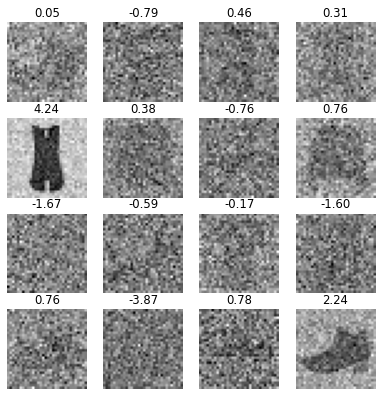

In [15]:
titles = [f'{o:.2f}' for o in ab[:16]]
show_images(xt[:16], imsize=1.7, titles=titles)

# Random Dummy model

In [10]:
class f(nn.Module):
    def __init__(self):
        super().__init__()
        self.blah = nn.Linear(1,1)
    def forward(self,x): return torch.full((len(x),), 0.5)

it literally predict the alphabar 0.5 everytime

In [11]:
cbs = [MetricsCB(),ProgressCB()]

In [12]:
lr = 1e-2
learn = TrainLearner(f(),dls, F.mse_loss, lr=lr, cbs=cbs)
learn.fit(1,train=False)

loss,epoch,train
3.565,0,eval


In [16]:
print(F.mse_loss(ab,torch.full((len(ab),), 0.5))) # same things
print(F.mse_loss(ab,torch.full(ab.shape, 0.5)))
print(F.mse_loss(torch.full(ab.shape, 0.5),ab))

tensor(4.2015)
tensor(4.2015)
tensor(4.2015)


In [17]:
def flat_mse(x,y): return F.mse_loss(x.flatten(), y.flatten())

To avoid errors or weird values because of broadcasting the wrong way, when dims aren't adjusted.

# Real model

In [18]:
def get_model(act=nn.ReLU, nfs=(16,32,64,128,256,512), norm=nn.BatchNorm2d):
    layers = [ResBlock(1, 16, ks=5, stride=1, act=act, norm=norm)]
    layers += [ResBlock(nfs[i], nfs[i+1], act=act, norm=norm, stride=2) for i in range(len(nfs)-1)]
    layers += [nn.Flatten(), nn.Dropout(0.2), nn.Linear(nfs[-1], 1, bias=False)]
    return nn.Sequential(*layers)

In [ ]:
opt_func = partial(optim.Adam, eps=1e-5)
epochs = 20
lr = 1e-2

tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), MetricsCB(), ProgressCB(plot=True)]
xtra = [BatchSchedCB(sched)]
act_gr = partial(GeneralRelu, leak=0.1, sub=0.4)
iw = partial(init_weights, leaky=0.1)
model = get_model(act_gr, norm=nn.BatchNorm2d).apply(iw)
learn = TrainLearner(model, dls, flat_mse, lr=lr, cbs=cbs+xtra, opt_func=opt_func)

In [ ]:
learn.fit(epochs)

loss reached -> 0.034

In [19]:
# torch.save(learn.model, '../models/noisepred_sig.pkl')
# tmodel = learn.model
tmodel = torch.load('../models/noisepred_sig.pkl',weights_only=False,map_location='cpu').cuda()

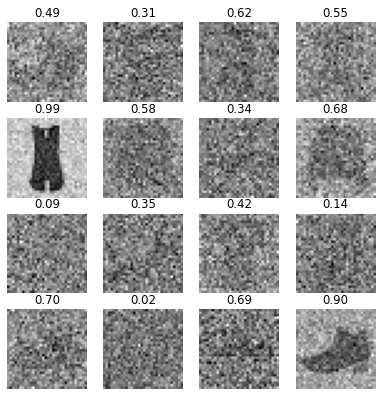

In [20]:
# Model Preds
with torch.no_grad(): a = to_cpu(tmodel(xt.cuda()).squeeze())
titles = [f'{o.sigmoid():.2f}' for o in a[:16]]
show_images(xt[:16], imsize=1.7, titles=titles)

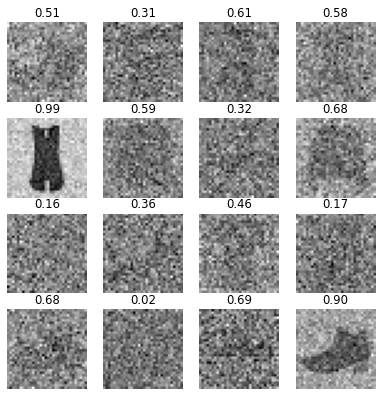

In [21]:
# Real Data
titles = [f'{o.sigmoid():.2f}' for o in ab[:16]]
show_images(xt[:16], imsize=1.7, titles=titles)

    The ResNet model was just to answer one question:
    "Can a neural network figure out how noisy an image is just by looking at it?"
    if Answer = yes it can → so the UNet without explicit timesteps might also work ✓
    Just a proof of concept experiment

# No TimeStamps Model

In [22]:
from diffusers import UNet2DModel
from torch.utils.data import DataLoader,default_collate

In [23]:
def abar(t): return (t*math.pi/2).cos()**2
def inv_abar(x): return x.sqrt().acos()*2/math.pi

In [24]:
def noisify(x0):
    device = x0.device
    n = len(x0)
    t = torch.rand((n,)).to(x0).clamp(0,0.999)
    ε = torch.randn(x0.shape).to(x0)
    abar_t = abar(t).reshape(-1, 1, 1, 1).to(device)
    xt = abar_t.sqrt()*x0 + (1-abar_t).sqrt()*ε
    return xt, ε  # <- we don't return (t)

In [25]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))-0.5 for o in b[xl]]
bs = 256
tds = dsd.with_transform(transformi)
dls = DataLoaders(dl_ddpm(tds['train'],bs=bs), dl_ddpm(tds['test'],bs=bs))

In [26]:
class UNet(UNet2DModel):
    def forward(self, x): return super().forward(x,0).sample

we made that the t=0, so model is going to find that it is not something that is useful because it is constant

In [27]:
def init_ddpm(model):
    for o in model.down_blocks:
        for p in o.resnets:
            p.conv2.weight.data.zero_()
            for p in fc.L(o.downsamplers): init.orthogonal_(p.conv.weight)

    for o in model.up_blocks:
        for p in o.resnets: p.conv2.weight.data.zero_()

    model.conv_out.weight.data.zero_()

In [24]:
lr = 4e-3
epochs = 25
opt_func = partial(optim.Adam, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), MixedPrecision(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched)]
model = UNet(in_channels=1, out_channels=1, block_out_channels=(32, 64, 128, 256), norm_num_groups=8)
init_ddpm(model)
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

- Remember that `MixedPrecision()` CB -> inherits from `TrainCB()`, so it have all training_fn defined
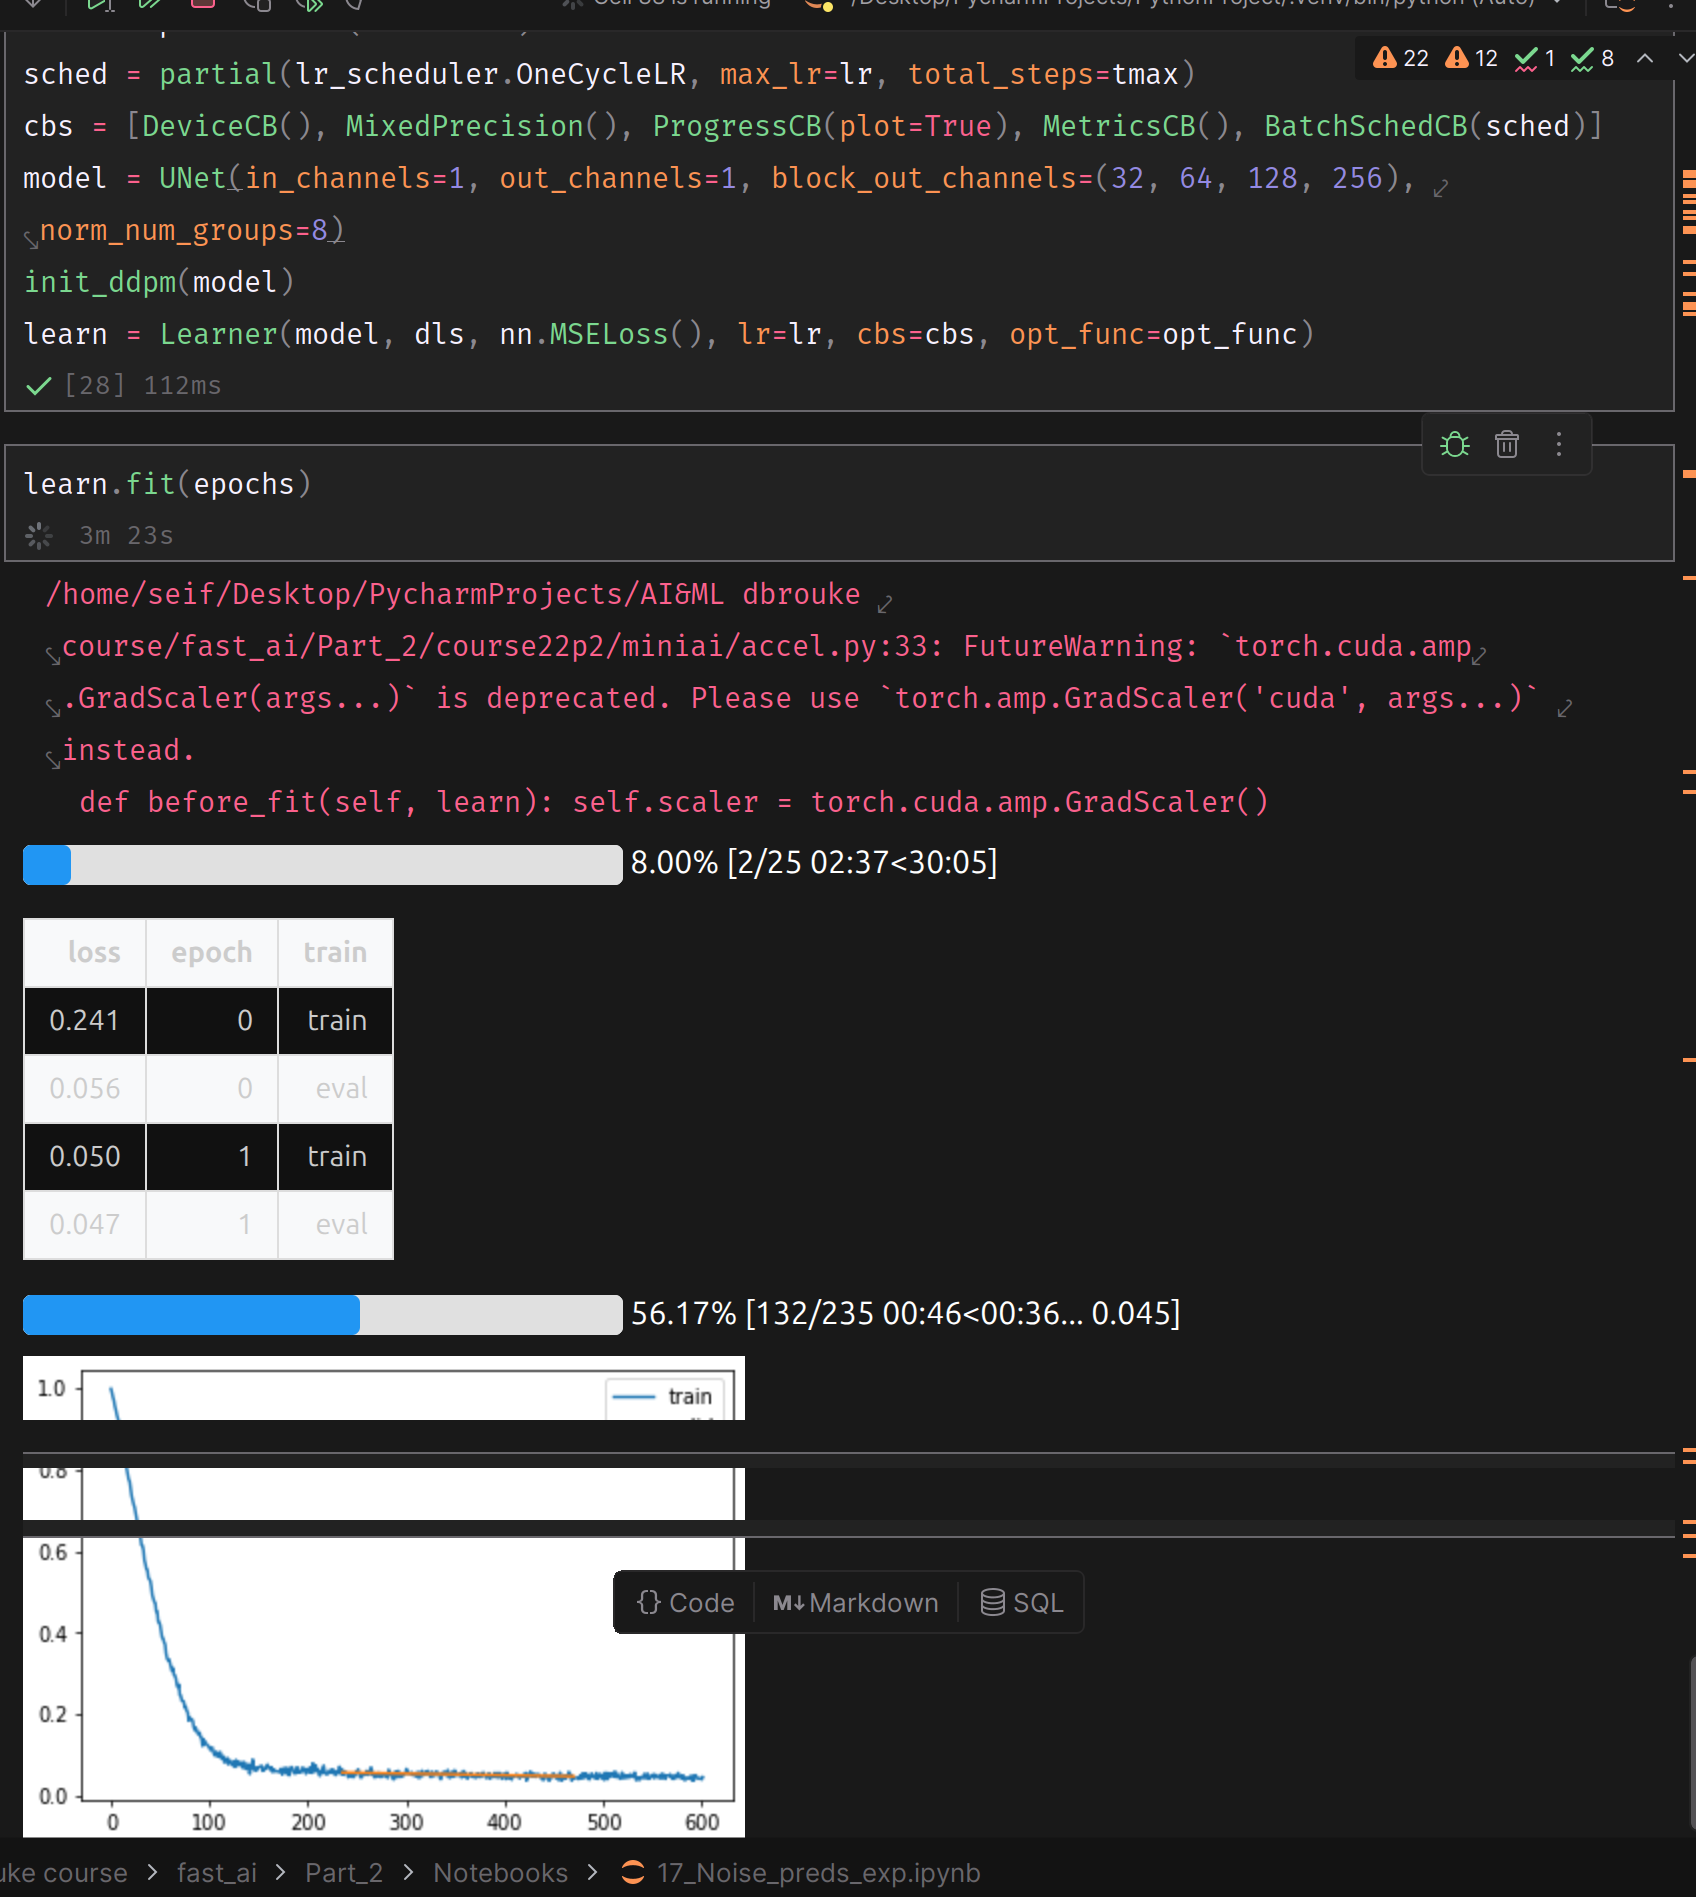

/home/seif/Desktop/PycharmProjects/AI&ML dbrouke course/fast_ai/Part_2/course22p2/miniai/accel.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self, learn): self.scaler = torch.cuda.amp.GradScaler()


loss,epoch,train
0.241,0,train
0.056,0,eval
0.050,1,train
0.047,1,eval
0.046,2,train
0.047,2,eval
0.043,3,train
0.041,3,eval
0.041,4,train
0.042,4,eval


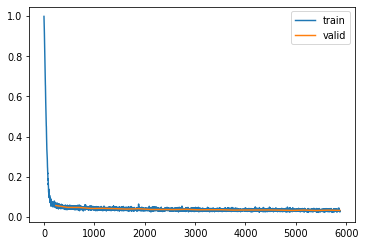

In [25]:
learn.fit(epochs)

In [28]:
# torch.save(learn.model, '../models/fashion_no-t.pkl')
model = learn.model = torch.load('../models/fashion_no-t.pkl',weights_only=False,map_location='cpu').cuda()

# Sampling

In [29]:
sz = (2048,1,32,32)

In [30]:
cmodel = torch.load('../models/data_aug2.pkl',weights_only=False,map_location='cpu').cuda()
del(cmodel[8])
del(cmodel[7])

@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))*2-1 for o in b[xl]]

bs = 2048
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

dt = dls.train
xb,yb = next(iter(dt))

ie = ImageEval(cmodel, dls, cbs=[DeviceCB()])

In [31]:
@torch.no_grad()
def sample(f, model, sz, n_steps, eta=1.):
    tsteps = torch.linspace(1-1/n_steps,0,n_steps)
    x_t = torch.randn(sz).to(model.device)
    preds = []
    for i, t in enumerate(progress_bar(tsteps)):
        abar_t = abar(t)
        noise = model(x_t)
        abar_t1 = abar(t-1/n_steps)  if t>=1/n_steps else torch.tensor(1)
        x_t,x_0_hat = f(x_t, noise, abar_t, abar_t1, 1-abar_t, 1-abar_t1, eta)
        preds.append(x_0_hat.float().cpu())
    return preds

## Classic DDIM(no T), (no Tmodel)

In [32]:
def ddim_step(x_t, noise, abar_t, abar_t1, bbar_t, bbar_t1, eta):
    sig = ((bbar_t1 / bbar_t) * (1 - abar_t / abar_t1)).sqrt() * eta
    x_0_hat = ((x_t - bbar_t.sqrt() * noise) / abar_t.sqrt()).clamp(-1.5,1.5) # SAFETY: clamp
    if bbar_t1<=sig**2+0.01: sig=0. # SAFETY:set to zero if very small or NaN (avoid root -ve)
    x_t = abar_t1.sqrt() * x_0_hat + (bbar_t1 - sig ** 2).sqrt() * noise
    x_t += sig * torch.randn(x_t.shape).to(x_t)
    return x_t,x_0_hat

In [55]:
preds = sample(ddim_step, model, sz, n_steps=100, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 02:17&lt;00:00]</div>

(19.9384765625, 0.40714213252067566) 
 (2.837158203125, -0.11189451813697815)


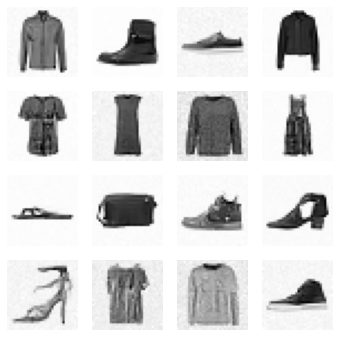

In [56]:
show_images(s[:16], imsize=1.5)

In [57]:
preds = sample(ddim_step, model, sz, n_steps=200, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="200" value="200"></progress> 100.00% [200/200 04:39&lt;00:00]</div>

(16.15380859375, 0.14463075995445251) 
 (2.837158203125, -0.11189451813697815)


In [58]:
preds = sample(ddim_step, model, sz, n_steps=50, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="50" value="50"></progress> 100.00% [50/50 01:08&lt;00:00]</div>

(18.66552734375, 0.20465125143527985) 
 (2.837158203125, -0.11189451813697815)


## DDIM(no T) + (T model)

In [33]:
def ddim_step_t_model(x_t, noise, abar_t, abar_t1, bbar_t, bbar_t1, eta):
    sig = ((bbar_t1/bbar_t).sqrt() * (1-abar_t/abar_t1).sqrt()) * eta
    with torch.no_grad(): a = tmodel(x_t)[...,None,None].sigmoid()
    med = a.median()
    a = a.clamp(med/2,med*2) # make sure numbers don't go too far
    x_0_hat = ((x_t-(1-a).sqrt()*noise) / a.sqrt()).clamp(-0.5,0.5)
    if bbar_t1<=sig**2+0.01: sig=0.  # set to zero if very small or NaN
    x_t = abar_t1.sqrt()*x_0_hat + (bbar_t1-sig**2).sqrt()*noise
    x_t += sig * torch.randn(x_t.shape).to(x_t)
    return x_t,x_0_hat

In [60]:
preds = sample(ddim_step_t_model, model, sz, n_steps=100, eta=1.)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 02:22&lt;00:00]</div>

(42.080810546875, 0.8003495335578918) 
 (2.837158203125, -0.11189451813697815)


In [61]:
preds = sample(ddim_step_t_model, model, sz, n_steps=100, eta=0.5)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 02:16&lt;00:00]</div>

(97.08642578125, 1.515290379524231) 
 (2.837158203125, -0.11189451813697815)


In [62]:
preds = sample(ddim_step_t_model, model, sz, n_steps=100, eta=0)
s = (preds[-1]*2)
print(f'{ie.fid(s), ie.kid(s)} \n {ie.fid(xb), ie.kid(xb)}')

<div><progress max="100" value="100"></progress> 100.00% [100/100 02:21&lt;00:00]</div>

(163.838134765625, 2.737919807434082) 
 (2.837158203125, -0.11189451813697815)


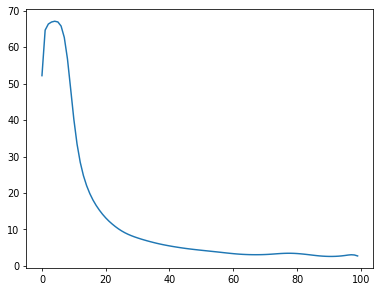

In [63]:
plt.plot([ie.kid((o*2).clamp(-1,1)) for o in preds]);

# Make a video

In [34]:
def sample(f, model, sz, n_steps, eta=1.):
    tsteps = torch.linspace(1-1/n_steps,0,n_steps)
    x_t = torch.randn(sz).to(model.device)
    preds_x0_hat = []
    preds_x_t = []
    for i, t in enumerate(progress_bar(tsteps)):
        abar_t = abar(t)
        noise = model(x_t)
        abar_t1 = abar(t-1/n_steps)  if t>=1/n_steps else torch.tensor(1)
        x_t,x_0_hat = f(x_t, noise, abar_t, abar_t1, 1-abar_t, 1-abar_t1, eta)
        preds_x0_hat.append(x_0_hat.float().cpu())
        preds_x_t.append(x_t.float().cpu())
    return preds_x0_hat,preds_x_t

In [36]:
sz = (4,1,32,32)

In [37]:
preds_x0_hat,preds_x_t = sample(ddim_step, model, sz, n_steps=50, eta=1.)

<div><progress max="50" value="50"></progress> 100.00% [50/50 00:01&lt;00:00]</div>

In [39]:
%matplotlib inline
import matplotlib.animation as animation
from IPython.display import display, HTML

# pick image index to show
idx = 0

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].set_title('x_0_hat (predicted clean)')
axes[1].set_title('x_t (noisy image)')
for ax in axes: ax.axis('off')

def _get_frame(i):
    # get one image from each, clip to [0,1] for display
    img_x0 = preds_x0_hat[i][idx].detach().permute(1,2,0).clamp(-1,1)*0.5+0.5
    img_xt = preds_x_t[i][idx].detach().permute(1,2,0).clamp(-1,1)*0.5+0.5
    im1 = axes[0].imshow(img_x0, animated=True)
    im2 = axes[1].imshow(img_xt, animated=True)
    return [im1, im2]

# take every N steps so video isnt too long
step = max(1, len(preds_x0_hat)//50)
frames = list(range(0, len(preds_x0_hat), step))

ims = [_get_frame(i) for i in frames]

animate = animation.ArtistAnimation(fig, ims, interval=100, blit=True, repeat_delay=1000)
plt.tight_layout()
plt.close(fig)
display(HTML(animate.to_jshtml()))